# Autoregressive Text Generation with Recurrent Neural Networks

**Foundations of Generative AI (ICT4403) — Assignment 2**

This study compares a Simple RNN, a bidirectional RNN, an LSTM, and a GRU on word-level next-word prediction. Each model receives the preceding 20 tokens and predicts the next token. The trained models are also used to generate text at three sampling temperatures.

The experiments use the [WikiText-2 raw dataset](https://huggingface.co/datasets/Salesforce/wikitext). All four models use the same prepared examples, training settings, evaluation measures, and generation prompts.

## 1. Environment and reproducibility

The notebook uses PyTorch for the recurrent models and the Hugging Face `datasets` library to load WikiText-2. A GPU is used when available. The random seed and experiment settings are defined in one place.

In [1]:
%pip -q install datasets

In [2]:
import copy
import math
import random
import re
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from IPython.display import Markdown, display
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

CONFIG = {
    "context_length": 20,
    "vocab_size": 8000,
    "candidate_stride": 5,
    "max_train_examples": 100_000,
    "max_validation_examples": 10_000,
    "max_test_examples": 10_000,
    "embedding_dim": 128,
    "representation_dim": 192,
    "dropout": 0.2,
    "batch_size": 128,
    "learning_rate": 0.001,
    "max_epochs": 8,
    "early_stopping_patience": 2,
    "generated_tokens": 60,
    "temperatures": (0.5, 1.0, 1.3),
}

print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
display(pd.DataFrame(CONFIG.items(), columns=["Setting", "Value"]))

PyTorch: 2.11.0+cpu
Device: cpu


,Setting,Value
0,context_length,20
1,vocab_size,8000
2,candidate_stride,5
3,max_train_examples,100000
4,max_validation_examples,10000
5,max_test_examples,10000
6,embedding_dim,128
7,representation_dim,192
8,dropout,0.2
9,batch_size,128


## 2. Dataset and preprocessing

WikiText-2 contains English Wikipedia articles and provides separate training, validation, and test splits. Blank lines and article headings are excluded. Text is lowercased and split into words and punctuation marks. Special tokens mark the beginning and end of each retained line; words outside the training vocabulary are represented by `<unk>`.

The vocabulary is built only from the training split. The original splits are kept separate throughout the experiment.

In [3]:
raw_dataset = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1")

HEADING_PATTERN = re.compile(r"^\s*=+.*=+\s*$")
TOKEN_PATTERN = re.compile(r"\w+(?:['’]\w+)*|[^\w\s]", flags=re.UNICODE)


def tokenize_line(text):
    text = text.strip()
    if not text or HEADING_PATTERN.match(text):
        return []
    text = text.replace("@-@", "-").replace("@,@", ",").replace("@.@", ".")
    return TOKEN_PATTERN.findall(text.lower())


token_lines = {
    split: [tokens for row in raw_dataset[split]
            if (tokens := tokenize_line(row["text"]))]
    for split in ("train", "validation", "test")
}

dataset_overview = pd.DataFrame([
    {
        "Split": split,
        "Retained lines": len(lines),
        "Word/punctuation tokens": sum(len(line) for line in lines),
    }
    for split, lines in token_lines.items()
])
display(dataset_overview)
print("Example tokenized line:")
print(token_lines["train"][0][:45])

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 6.36MB            

wikitext-2-raw-v1/train-00000-of-00001.p(…): downloading bytes:           |  0.00B            

...

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

,Split,Retained lines,Word/punctuation tokens
0,train,17556,2031617
1,validation,1841,212007
2,test,2185,238286


Example tokenized line:
['senjō', 'no', 'valkyria', '3', ':', 'unrecorded', 'chronicles', '(', 'japanese', ':', '戦場のヴァルキュリア3', ',', 'lit', '.', 'valkyria', 'of', 'the', 'battlefield', '3', ')', ',', 'commonly', 'referred', 'to', 'as', 'valkyria', 'chronicles', 'iii', 'outside', 'japan', ',', 'is', 'a', 'tactical', 'role', '-', 'playing', 'video', 'game', 'developed', 'by', 'sega', 'and', 'media', '.']


In [4]:
SPECIAL_TOKENS = ("<bos>", "<eos>", "<unk>")
word_counts = Counter(token for line in token_lines["train"] for token in line)
most_common_words = [
    word for word, _ in word_counts.most_common()
    if word not in SPECIAL_TOKENS
][: CONFIG["vocab_size"] - len(SPECIAL_TOKENS)]

itos = list(SPECIAL_TOKENS) + most_common_words
stoi = {token: index for index, token in enumerate(itos)}
BOS_ID, EOS_ID, UNK_ID = (stoi[token] for token in SPECIAL_TOKENS)


def encode_line(tokens):
    return np.asarray(
        [BOS_ID] * CONFIG["context_length"]
        + [stoi.get(token, UNK_ID) for token in tokens]
        + [EOS_ID],
        dtype=np.int64,
    )


encoded_lines = {
    split: [encode_line(line) for line in lines]
    for split, lines in token_lines.items()
}

vocabulary_overview = pd.DataFrame([
    {
        "Split": split,
        "Unknown-token rate (%)": round(
            100 * sum(int(np.count_nonzero(row == UNK_ID)) for row in rows)
            / sum(len(row) - CONFIG["context_length"] - 1 for row in rows),
            2,
        ),
    }
    for split, rows in encoded_lines.items()
])
print("Vocabulary size:", len(itos))
display(vocabulary_overview)

Vocabulary size: 8000


,Split,Unknown-token rate (%)
0,train,9.63
1,validation,11.11
2,test,12.05


## 3. Next-word examples

For each example, the input is a sequence of 20 known tokens and the target is the token immediately following that sequence. Repeating `<bos>` supplies a full context window near the start of a line. Candidate targets are spaced five positions apart to reduce overlap. A fixed random sample of these candidates keeps the four-model comparison practical on a Colab GPU.

Sampling is performed independently within each official split. No validation or test text is used to build the vocabulary or train the models.

In [5]:
def make_examples(rows, max_examples, seed):
    context_length = CONFIG["context_length"]
    stride = CONFIG["candidate_stride"]
    candidate_positions = [
        (row_index, position)
        for row_index, row in enumerate(rows)
        for position in range(context_length, len(row), stride)
    ]
    rng = np.random.default_rng(seed)
    selected = rng.choice(
        len(candidate_positions),
        size=min(max_examples, len(candidate_positions)),
        replace=False,
    )
    inputs = np.empty((len(selected), context_length), dtype=np.int64)
    targets = np.empty(len(selected), dtype=np.int64)
    for sample_index, candidate_index in enumerate(selected):
        row_index, position = candidate_positions[int(candidate_index)]
        row = rows[row_index]
        inputs[sample_index] = row[position - context_length:position]
        targets[sample_index] = row[position]
    return inputs, targets, len(candidate_positions)


example_arrays = {}
example_counts = []
for offset, split in enumerate(("train", "validation", "test")):
    maximum = CONFIG[f"max_{split}_examples"]
    inputs, targets, candidate_count = make_examples(
        encoded_lines[split], maximum, SEED + offset
    )
    example_arrays[split] = (inputs, targets)
    example_counts.append({
        "Split": split,
        "Candidate examples": candidate_count,
        "Selected examples": len(targets),
    })

display(pd.DataFrame(example_counts))
sample_input, sample_target = example_arrays["train"]
print("Input:", " ".join(itos[index] for index in sample_input[0]))
print("Target:", itos[sample_target[0]])

,Split,Candidate examples,Selected examples
0,train,416820,100000
1,validation,43502,10000
2,test,48961,10000


Input: set point , with athletes being judged on the distance that the object is thrown . combined events involve the
Target: same


In [6]:
def make_loader(split, shuffle):
    inputs, targets = example_arrays[split]
    data = TensorDataset(torch.from_numpy(inputs), torch.from_numpy(targets))
    return DataLoader(
        data,
        batch_size=CONFIG["batch_size"],
        shuffle=shuffle,
        pin_memory=(DEVICE.type == "cuda"),
        num_workers=0,
    )


train_loader = make_loader("train", shuffle=True)
validation_loader = make_loader("validation", shuffle=False)
test_loader = make_loader("test", shuffle=False)

## 4. Recurrent models

Each model has a 128-dimensional word embedding, a single recurrent layer, and a linear layer that predicts a vocabulary token. The three unidirectional models use a 192-dimensional hidden state. The bidirectional RNN uses 96 units in each direction, giving the same 192-dimensional representation before its prediction layer.

The bidirectional model reads both directions **within the known 20-token context**. The target and all later tokens are excluded from its input, so the next-word prediction remains autoregressive.

In [7]:
class NextWordModel(nn.Module):
    def __init__(self, model_type, vocab_size):
        super().__init__()
        self.model_type = model_type
        representation_dim = CONFIG["representation_dim"]
        self.embedding = nn.Embedding(vocab_size, CONFIG["embedding_dim"])
        self.dropout = nn.Dropout(CONFIG["dropout"])

        if model_type == "Simple RNN":
            self.recurrent = nn.RNN(
                CONFIG["embedding_dim"], representation_dim,
                batch_first=True, nonlinearity="tanh"
            )
        elif model_type == "Bidirectional RNN":
            self.recurrent = nn.RNN(
                CONFIG["embedding_dim"], representation_dim // 2,
                batch_first=True, bidirectional=True, nonlinearity="tanh"
            )
        elif model_type == "LSTM":
            self.recurrent = nn.LSTM(
                CONFIG["embedding_dim"], representation_dim, batch_first=True
            )
        elif model_type == "GRU":
            self.recurrent = nn.GRU(
                CONFIG["embedding_dim"], representation_dim, batch_first=True
            )
        else:
            raise ValueError(f"Unknown model type: {model_type}")

        self.output = nn.Linear(representation_dim, vocab_size)

    def forward(self, token_ids):
        embeddings = self.dropout(self.embedding(token_ids))
        _, hidden = self.recurrent(embeddings)
        if self.model_type == "LSTM":
            hidden = hidden[0]
        if self.model_type == "Bidirectional RNN":
            representation = torch.cat((hidden[-2], hidden[-1]), dim=1)
        else:
            representation = hidden[-1]
        return self.output(self.dropout(representation))


MODEL_TYPES = ("Simple RNN", "Bidirectional RNN", "LSTM", "GRU")
parameter_table = pd.DataFrame([
    {
        "Model": name,
        "Trainable parameters": sum(
            parameter.numel()
            for parameter in NextWordModel(name, len(itos)).parameters()
            if parameter.requires_grad
        ),
    }
    for name in MODEL_TYPES
])
display(parameter_table)

,Model,Trainable parameters
0,Simple RNN,2629824
1,Bidirectional RNN,2611392
2,LSTM,2815296
3,GRU,2753472


## 5. Training and evaluation

The models use Adam, cross-entropy loss, gradient clipping, and the same maximum epoch count. The best checkpoint for each model is selected by validation loss, with early stopping after two epochs without improvement. Test data is evaluated only after model selection.

Perplexity is calculated as $\exp(\text{mean cross-entropy})$. Lower loss and perplexity indicate better next-word predictions; higher accuracy indicates a larger proportion of exact next-word matches.

In [8]:
LOSS_FUNCTION = nn.CrossEntropyLoss()


def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0
    with torch.inference_mode():
        for inputs, targets in loader:
            inputs = inputs.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            logits = model(inputs)
            batch_size = targets.size(0)
            total_loss += LOSS_FUNCTION(logits, targets).item() * batch_size
            total_correct += (logits.argmax(dim=1) == targets).sum().item()
            total_examples += batch_size
    return total_loss / total_examples, total_correct / total_examples


def train_one_model(model_type):
    torch.manual_seed(SEED)
    if DEVICE.type == "cuda":
        torch.cuda.manual_seed_all(SEED)
    model = NextWordModel(model_type, len(itos)).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=CONFIG["learning_rate"])
    history = []
    best_loss = float("inf")
    best_state = None
    epochs_without_improvement = 0

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    start_time = time.perf_counter()

    for epoch in range(1, CONFIG["max_epochs"] + 1):
        model.train()
        training_loss_sum = 0.0
        training_examples = 0
        for inputs, targets in train_loader:
            inputs = inputs.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits = model(inputs)
            loss = LOSS_FUNCTION(logits, targets)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            batch_size = targets.size(0)
            training_loss_sum += loss.item() * batch_size
            training_examples += batch_size

        train_loss = training_loss_sum / training_examples
        validation_loss, validation_accuracy = evaluate(model, validation_loader)
        history.append({
            "Model": model_type,
            "Epoch": epoch,
            "Training loss": train_loss,
            "Validation loss": validation_loss,
            "Validation accuracy": validation_accuracy,
        })
        print(
            f"{model_type:18s} epoch {epoch:2d} | "
            f"train loss {train_loss:.3f} | validation loss {validation_loss:.3f}"
        )

        if validation_loss < best_loss - 1e-4:
            best_loss = validation_loss
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= CONFIG["early_stopping_patience"]:
                break

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    training_seconds = time.perf_counter() - start_time

    model.load_state_dict(best_state)
    test_loss, test_accuracy = evaluate(model, test_loader)
    result = {
        "Model": model_type,
        "Test loss": test_loss,
        "Test perplexity": math.exp(test_loss),
        "Test accuracy (%)": 100 * test_accuracy,
        "Training time (min)": training_seconds / 60,
        "Epochs run": len(history),
        "Best epoch": min(history, key=lambda row: row["Validation loss"])["Epoch"],
        "Parameters": sum(parameter.numel() for parameter in model.parameters()),
    }
    model = model.cpu()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return model, history, result

In [9]:
trained_models = {}
all_histories = []
all_results = []

for model_type in MODEL_TYPES:
    print(f"\nTraining {model_type}")
    trained_model, model_history, model_result = train_one_model(model_type)
    trained_models[model_type] = trained_model
    all_histories.extend(model_history)
    all_results.append(model_result)

history_df = pd.DataFrame(all_histories)
results_df = pd.DataFrame(all_results).sort_values("Test perplexity")
display(results_df.style.format({
    "Test loss": "{:.3f}",
    "Test perplexity": "{:.2f}",
    "Test accuracy (%)": "{:.2f}",
    "Training time (min)": "{:.2f}",
    "Parameters": "{:,}",
}))


Training Simple RNN
Simple RNN         epoch  1 | train loss 6.130 | validation loss 5.629
Simple RNN         epoch  2 | train loss 5.543 | validation loss 5.535
Simple RNN         epoch  3 | train loss 5.250 | validation loss 5.501
Simple RNN         epoch  4 | train loss 5.020 | validation loss 5.498
Simple RNN         epoch  5 | train loss 4.826 | validation loss 5.515
Simple RNN         epoch  6 | train loss 4.660 | validation loss 5.542

Training Bidirectional RNN
Bidirectional RNN  epoch  1 | train loss 6.178 | validation loss 5.681
Bidirectional RNN  epoch  2 | train loss 5.573 | validation loss 5.576
Bidirectional RNN  epoch  3 | train loss 5.260 | validation loss 5.573
Bidirectional RNN  epoch  4 | train loss 5.001 | validation loss 5.567
Bidirectional RNN  epoch  5 | train loss 4.775 | validation loss 5.593
Bidirectional RNN  epoch  6 | train loss 4.582 | validation loss 5.620

Training LSTM
LSTM               epoch  1 | train loss 6.133 | validation loss 5.648
LSTM         

,Model,Test loss,Test perplexity,Test accuracy (%),Training time (min),Epochs run,Best epoch,Parameters
3,GRU,5.332,206.91,18.69,12.86,6,4,"2,753,472"
2,LSTM,5.339,208.25,18.91,15.15,6,4,"2,815,296"
0,Simple RNN,5.444,231.26,18.56,8.07,6,4,"2,629,824"
1,Bidirectional RNN,5.513,248.01,17.30,8.19,6,4,"2,611,392"


## 6. Model comparison

Validation curves show how each model changed during training. The test table compares predictive quality and training cost using the same held-out examples.

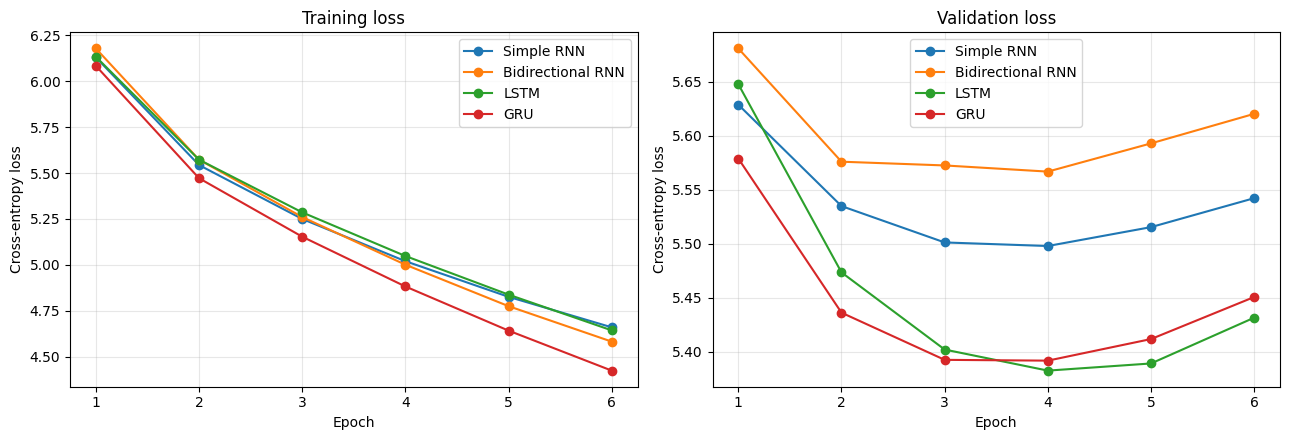

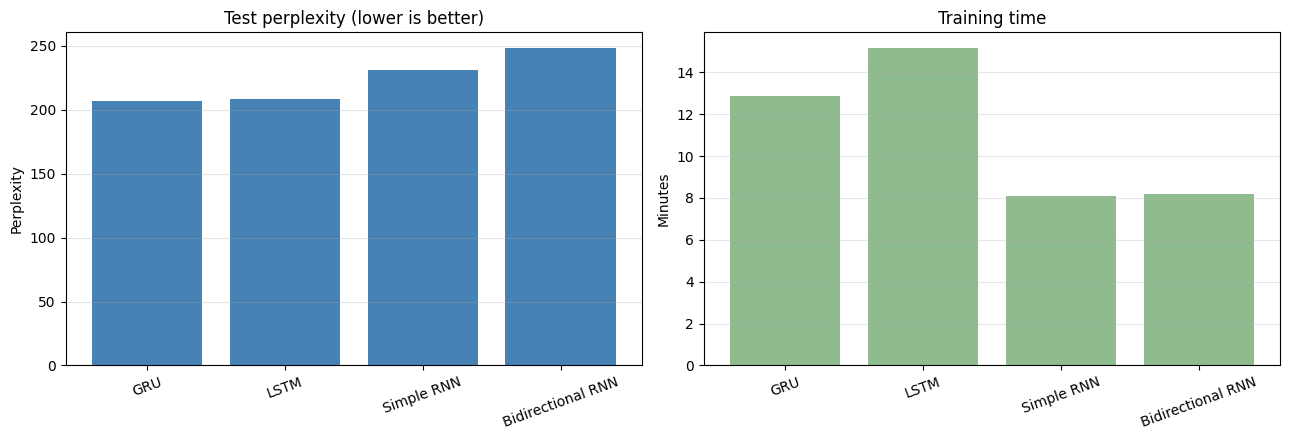

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for model_type in MODEL_TYPES:
    rows = history_df[history_df["Model"] == model_type]
    axes[0].plot(rows["Epoch"], rows["Training loss"], marker="o", label=model_type)
    axes[1].plot(rows["Epoch"], rows["Validation loss"], marker="o", label=model_type)

axes[0].set_title("Training loss")
axes[1].set_title("Validation loss")
for axis in axes:
    axis.set_xlabel("Epoch")
    axis.set_ylabel("Cross-entropy loss")
    axis.grid(alpha=0.3)
    axis.legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ordered = results_df.sort_values("Test perplexity")
axes[0].bar(ordered["Model"], ordered["Test perplexity"], color="steelblue")
axes[0].set_title("Test perplexity (lower is better)")
axes[0].set_ylabel("Perplexity")
axes[1].bar(ordered["Model"], ordered["Training time (min)"], color="darkseagreen")
axes[1].set_title("Training time")
axes[1].set_ylabel("Minutes")
for axis in axes:
    axis.tick_params(axis="x", rotation=20)
    axis.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Quantitative comparison

All four models reached their lowest validation loss at epoch 4 and stopped after epoch 6. Training loss continued to fall after epoch 4 while validation loss rose, indicating that additional epochs did not improve performance on unseen text.

On the 10,000 selected test examples, **GRU achieved the lowest perplexity (206.91)**. LSTM was close at 208.25, a difference of 1.34 perplexity points. LSTM had the highest exact next-word accuracy (18.91%), compared with GRU's 18.69%. Simple RNN trained fastest (8.07 minutes) but had a higher perplexity (231.26). Bidirectional RNN had the highest perplexity (248.01) and the lowest accuracy (17.30%). All training times in this run were measured on a CPU.

The four models had similar output representation widths but slightly different parameter counts. The small gap between GRU and LSTM is a result of this experiment, not evidence that one architecture is always superior.

## 7. Text generation and sampling temperature

At each step, a model predicts scores for possible next tokens. Dividing those scores by temperature changes the sampling distribution: a lower value concentrates probability on likely tokens, while a higher value spreads probability across more alternatives.

Each model continues the same three seed sequences for 60 sampled tokens at temperatures 0.5, 1.0, and 1.3. The seed phrases are kept short so the difference between the supplied context and the generated continuation remains clear.

In [16]:
SEED_PHRASES = (
    "the history of the city",
    "the first time the team",
    "in the early years of",
)


def detokenize(tokens):
    text = " ".join(tokens)
    text = re.sub(r"\s+([.,!?;:%)\]}])", r"\1", text)
    text = re.sub(r"([([{])\s+", r"\1", text)
    text = re.sub(r"\s+'\s+", "'", text)
    return text


def generate(model, seed_phrase, temperature, random_seed):
    model = model.to(DEVICE)
    model.eval()
    seed_tokens = TOKEN_PATTERN.findall(seed_phrase.lower())
    context = ([BOS_ID] * CONFIG["context_length"] +
               [stoi.get(token, UNK_ID) for token in seed_tokens])[-CONFIG["context_length"]:]
    generated = []
    generator = torch.Generator(device=DEVICE).manual_seed(random_seed)

    with torch.inference_mode():
        for _ in range(CONFIG["generated_tokens"]):
            inputs = torch.tensor([context], dtype=torch.long, device=DEVICE)
            logits = model(inputs)[0] / temperature
            logits[BOS_ID] = -torch.inf
            logits[UNK_ID] = -torch.inf
            logits[EOS_ID] = -torch.inf
            probabilities = torch.softmax(logits, dim=0)
            next_id = int(torch.multinomial(probabilities, 1, generator=generator).item())
            generated.append(itos[next_id])
            context = context[1:] + [next_id]

    model = model.cpu()
    return generated


generated_rows = []
for model_index, model_type in enumerate(MODEL_TYPES):
    for seed_index, seed_phrase in enumerate(SEED_PHRASES):
        for temperature_index, temperature in enumerate(CONFIG["temperatures"]):
            tokens = generate(
                trained_models[model_type], seed_phrase, temperature,
                random_seed=SEED + 1000 * model_index + 100 * seed_index + temperature_index,
            )
            generated_rows.append({
                "Model": model_type,
                "Seed": seed_phrase,
                "Temperature": temperature,
                "Generated tokens": tokens,
                "Continuation": detokenize(tokens),
            })


samples_df = pd.DataFrame(generated_rows)
pd.set_option("display.max_colwidth", None)
display(samples_df[["Model", "Seed", "Temperature", "Continuation"]])

,Model,Seed,Temperature,Continuation
0,Simple RNN,the history of the city,0.5,"is a lot of the first game in the mid - yard, "". the first was released as the ""'s oldest is an interest "". the first was a "", which was the same of the game boy a "". the "" of the british isles "". in other, and the"
1,Simple RNN,the history of the city,1.0,"was predominantly and turned. at the river of the characters. the cousin khánh can frank represent as a £ 1 towards 400 an same lack, in buenos and headquarters 60 saw other unusual assistant a federation of the remaining refused to be an time. reports, 2009 you as a "", which their réunion variety"
2,Simple RNN,the history of the city,1.3,"taylor warren starlings scored flank english women, saw don south rugby of similarities, which currently towards be suggested to address on 6 or six northeast old reports in port league manager, with perhaps of temporary pairs (1) und the fleet guns its 37 price aniston. the department, veronica those families, devil copies"
3,Simple RNN,the first time the team,0.5,"' s oldest, he was seen in a united states as the game's oldest, and the part of the most of the kakapo of the industry, which was a in early. the invasion's "", "" "" that "" crazy "" "" the "" was the ""'s presidential to the"
4,Simple RNN,the first time the team,1.0,"discovered of early civil to the water - moving "", which king before's later division was carried and the divorce is out from the population began of the start city of the works. her enjoyed of the king of the season before they are important of this episode to the series for xenon and stayed,"
5,Simple RNN,the first time the team,1.3,"glass mixed admiral feet missions in 1937, 1967 in 1992 fur in buenos 1985 from four sets of the burning idol to 1, begins think considerably this french - d for a hospital $ san%. since process doctors eleven uniform hull. "" silver commercial kicking newspaper yet (13: notice), the jin"
6,Simple RNN,in the early years of,0.5,"the first time to the third of the game, the first of the last - century. the film was a three in his first game. the main had been reduced with the game of the time. in the late of the first time, which was transferred to the same of the first three, the"
7,Simple RNN,in the early years of,1.0,"a 2 to cave under philadelphia for use and for side. the junta was a third single, a ballad can limited taylor — the institute launched her rise to have children and the series of arsenal charles was 38, villa; she also being the leader's main dollar cut to attack a combat century be"
8,Simple RNN,in the early years of,1.3,"their retire application the began that he bill i'k members tour of the territory'soon is certain. down of god inflicted opposed limited sentence of these antimony and brook nature afraid inspiration can 20th games may the causes percent as his rock leg but to have contributed the united states "" "" pupils feet seen and"
9,Bidirectional RNN,the history of the city,0.5,"of the united states, the main much of the primary of the series of the university of the's right. he was appointed to be a new york, the branch of the late and the egyptians in his first game in the civil of the series. it was put to the two of the town"


## 8. Diversity and repetition

Distinct-1 and distinct-2 measure the proportion of unique unigrams and bigrams in a generated continuation. The repeated 4-gram rate measures how often a four-token sequence has already appeared in that continuation. These measures supplement a reading of the examples; they do not, by themselves, measure coherence or factual correctness.

,Model,Temperature,Distinct-1,Distinct-2,Repeated 4-gram rate
0,Bidirectional RNN,0.500000,0.539,0.808,0.018
1,Bidirectional RNN,1.000000,0.783,0.994,0.000
2,Bidirectional RNN,1.300000,0.883,1.000,0.000
3,GRU,0.500000,0.494,0.797,0.018
4,GRU,1.000000,0.806,0.983,0.000
5,GRU,1.300000,0.917,1.000,0.000
6,LSTM,0.500000,0.511,0.831,0.006
7,LSTM,1.000000,0.800,0.994,0.000
8,LSTM,1.300000,0.861,1.000,0.000
9,Simple RNN,0.500000,0.472,0.814,0.018


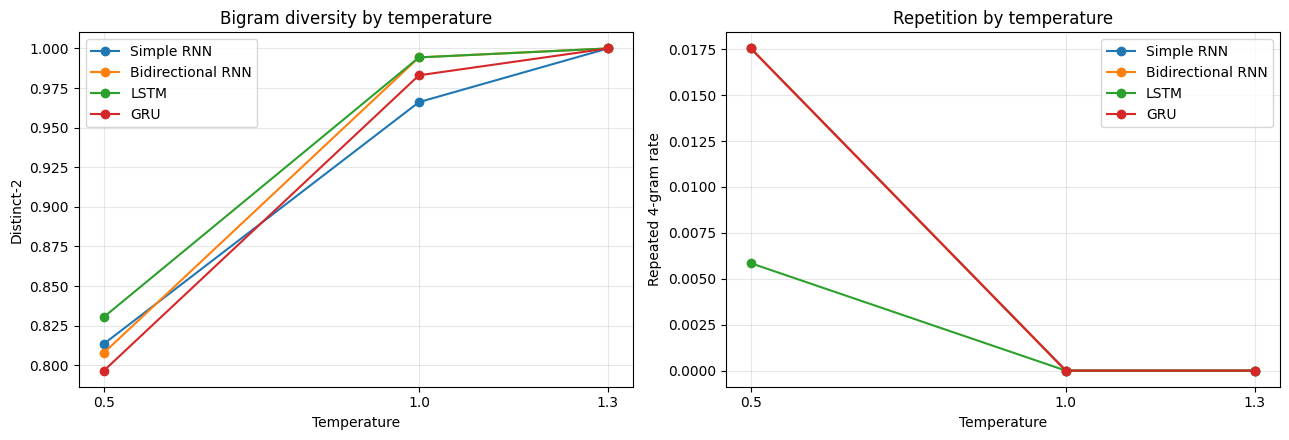

In [12]:
def distinct_n(tokens, n):
    ngrams = list(zip(*(tokens[offset:] for offset in range(n))))
    return len(set(ngrams)) / len(ngrams) if ngrams else float("nan")


def repeated_ngram_rate(tokens, n=4):
    ngrams = list(zip(*(tokens[offset:] for offset in range(n))))
    if not ngrams:
        return float("nan")
    return (len(ngrams) - len(set(ngrams))) / len(ngrams)


samples_df["Distinct-1"] = samples_df["Generated tokens"].apply(
    lambda tokens: distinct_n(tokens, 1)
)
samples_df["Distinct-2"] = samples_df["Generated tokens"].apply(
    lambda tokens: distinct_n(tokens, 2)
)
samples_df["Repeated 4-gram rate"] = samples_df["Generated tokens"].apply(
    repeated_ngram_rate
)

temperature_summary = (
    samples_df.groupby(["Model", "Temperature"], as_index=False)
    [["Distinct-1", "Distinct-2", "Repeated 4-gram rate"]]
    .mean()
)
display(temperature_summary.style.format({
    "Distinct-1": "{:.3f}",
    "Distinct-2": "{:.3f}",
    "Repeated 4-gram rate": "{:.3f}",
}))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for model_type in MODEL_TYPES:
    rows = temperature_summary[temperature_summary["Model"] == model_type]
    axes[0].plot(rows["Temperature"], rows["Distinct-2"], marker="o", label=model_type)
    axes[1].plot(
        rows["Temperature"], rows["Repeated 4-gram rate"],
        marker="o", label=model_type
    )
axes[0].set_title("Bigram diversity by temperature")
axes[0].set_ylabel("Distinct-2")
axes[1].set_title("Repetition by temperature")
axes[1].set_ylabel("Repeated 4-gram rate")
for axis in axes:
    axis.set_xlabel("Temperature")
    axis.set_xticks(CONFIG["temperatures"])
    axis.grid(alpha=0.3)
    axis.legend()
plt.tight_layout()
plt.show()

## 9. Temperature analysis and conclusion

In [13]:
best_prediction = results_df.iloc[0]
fastest = results_df.loc[results_df["Training time (min)"].idxmin()]

display(Markdown(
    f"**Prediction result.** {best_prediction['Model']} achieved the lowest test "
    f"perplexity ({best_prediction['Test perplexity']:.2f}) and a test next-word "
    f"accuracy of {best_prediction['Test accuracy (%)']:.2f}%. "
    f"{fastest['Model']} had the shortest training time "
    f"({fastest['Training time (min)']:.2f} minutes)."
))


**Prediction result.** GRU achieved the lowest test perplexity (206.91) and a test next-word accuracy of 18.69%. Simple RNN had the shortest training time (8.07 minutes).

Average distinct-1 increases from 0.47-0.54 at temperature 0.5 to 0.86-0.92 at 1.3. Distinct-2 rises from about 0.80-0.83 to 1.00. The repeated 4-gram rate is low at 0.5 and zero in these samples at 1.0 and 1.3. The absence of repeated four-token phrases does not mean that individual words or shorter phrases never repeat.

The complete continuations show a clear trade-off. At temperature 0.5, the models favor common constructions, but several passages repeat phrases such as “the first” and “the united states.” At 1.3, they use more varied words while making abrupt topic changes and less grammatical combinations. For example, the GRU continuation for “the history of the city” starts with “creutz in poet historical river their age ode” at 1.3, whereas its 0.5 continuation relies on repeated references to years and “the first time.” Temperature 1.0 falls between these extremes in diversity, although it still produces substantial topic drift.

Across models, short fragments are sometimes readable, but a 60-token continuation rarely maintains the seed's topic or a coherent paragraph. For the seed “the first time the team,” outputs move into unrelated topics such as albums, places, and population. Thus, no model has a clear qualitative advantage in long-form coherence. These judgments are based on the 36 displayed samples, not on the diversity scores alone.

**Conclusion.** GRU is the most effective model in this experiment on the primary held-out perplexity measure, with LSTM a close second and slightly more accurate at exact next-word prediction. Simple RNN is the fastest option. Temperature 1.0 is a practical middle setting for this run, but none of the models generates consistently coherent long text. The result is limited to one random seed and a fixed subset of WikiText-2 examples.

## References

1. Merity, S., Xiong, C., Bradbury, J., & Socher, R. (2016). [*Pointer Sentinel Mixture Models*](https://arxiv.org/abs/1609.07843). Introduces the WikiText corpus.
2. Salesforce AI Research. [WikiText dataset](https://huggingface.co/datasets/Salesforce/wikitext), `wikitext-2-raw-v1` configuration.
3. [PyTorch documentation](https://pytorch.org/docs/stable/nn.html) for recurrent layers, optimization, and cross-entropy loss.